In [1]:
from IPython.display import Image, display

# Dimensionality reduction
- **Curse of dimensionality:** In theory, high-dimensional data contains more information, but in practice this is not the case. Higher-dimensional data often contains more noise and redundancy, and therefore, adding more information does not provide benfits for downstream analysis.
- Dimensionality reduction embeds the high-dimensional data into a lower-dimensional space. The low-dimensional representation still captures the underlying structure of the data while having as few dimensions as possible.
- A comparison of different dimensionality reduction method suggest `t-distributed stochastic neighbor embedding (t-SNE)` to yield the best overall performance while `Uniform manifold approximation and projection (UMAP)` show the highest stability and separated the original cell populations best.

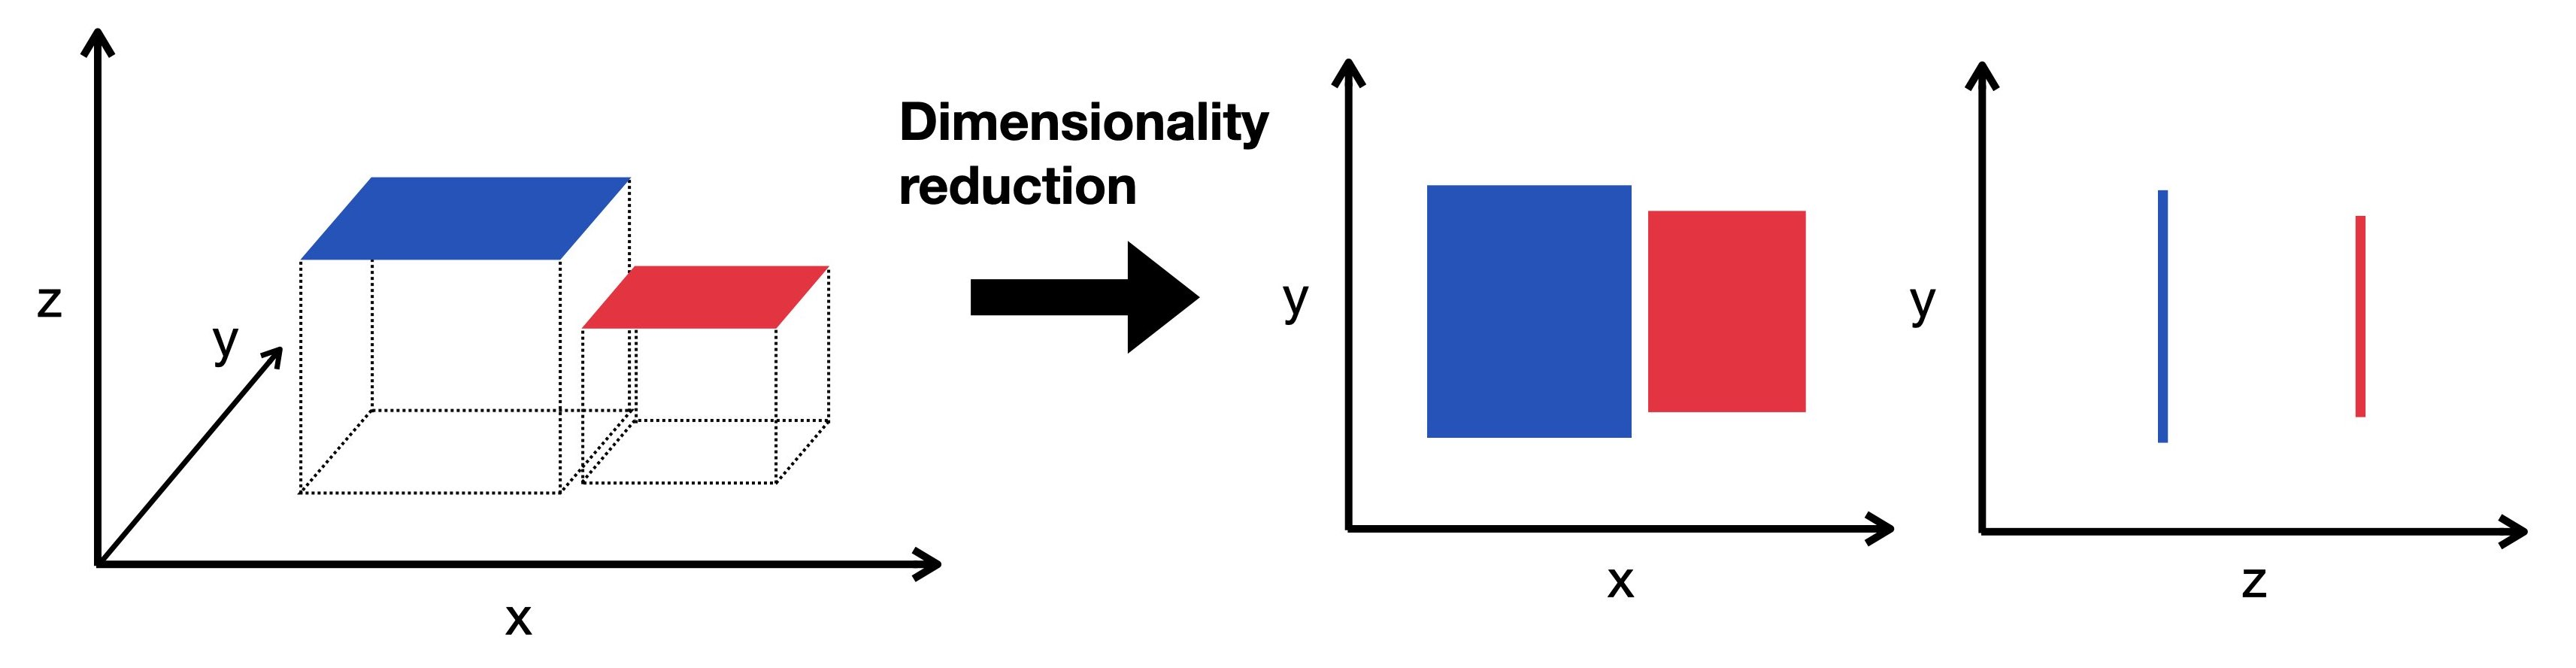

In [2]:
display(Image(filename="../../images/dimensionality_reduction.jpeg"))

In [3]:
import anndata as ad
import lamindb as ln
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

# Suppress verbose logging from Scanpy
sc.settings.verbosity = 0

# Set figure parameters for clean, minimal plots
sc.set_figure_params(dpi=80, facecolor="white", frameon=False)

ln.connect("theislab/sc-best-practices")

→ connected lamindb: anonymous/intermediate_data
! re-setting django: avoid this by clearing the default instance on the command line via: lamin disconnect
→ connected lamindb: theislab/sc-best-practices
! connected in read-only mode, please use ln.DB("theislab/sc-best-practices") instead


In [4]:
# Loading the dataset after quality control, normalization and feature selection
af = ln.Artifact.connect("theislab/sc-best-practices").get(
    key="preprocessing_visualization/s4d8_feature_selection.h5ad", is_latest=True
)
adata = af.load()

## Why should we use normalized data for dimensionality reduction?
- Gene expression is typically heavily right-skewed with many zeros and a few highly expressed genes. Log transformation helps normalize this distribution, making it more symmetric and reducing the impact of extreme values. This prevents highly expressed genes from dominating any distance calculations.
- Biological signals in expression data follow multiplicative rather than additive patterns. Log transformation converts multiplicative relationships to additive ones, which most dimensionality reduction algorithms (PCA, t-SNE, UMAP) are designed to detect.
- Variance in raw expression data scales with mean expression levels. Log transformation stabilizes this variance, preventing highly expressed genes from dominating the analysis.

In [5]:
adata.X = adata.layers["scran_normalization"]

In [6]:
adata

AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    layers: 'analytic_pearson_residuals', 'counts', 'log1p_norm', 'scran_normalization', 'soupX_counts', None (.X)

# PCA
- PCA creates a new set of uncorrelated variables called principal components (PCs), via an orthogonal transformation of the original dataset.
- The PCs are linear combinations of features in the original dataset and are ranked in decreasing order of variance to define the transformation.
- The first PC typically captures the greatest amount of variance. PC1 is the direction where the data is most spread out, and PC2 is the next most variable direction, perpendicular to PC1.
- PCs with the lowest variance are discarded to effectively reduce the dimensionality of the data without loosing information.
- Highly interpretable and computationally efficient. However, as scRNA-seq datasets are sparse due to dropout events and therefore, highly non-linear, visualization with the linear dimensionality reduction technique PCA is not appropriate.
- PCA is used to select the top 10-50 PCs which are used for downstream analysis.

**N.B.:** There is a choice between whether we want to scale genes before PCA or not. Scaling wights all genes equally for downstream analysis while not scaling keeps the magnitude of expression as a proxy for how informative a gene is. This is not the same as centering carried out in `sc.pp.pca`

In [7]:
adata.var["highly_variable"] = adata.var["highly_deviant"]
sc.pp.pca(adata, svd_solver="arpack", mask_var="highly_variable")

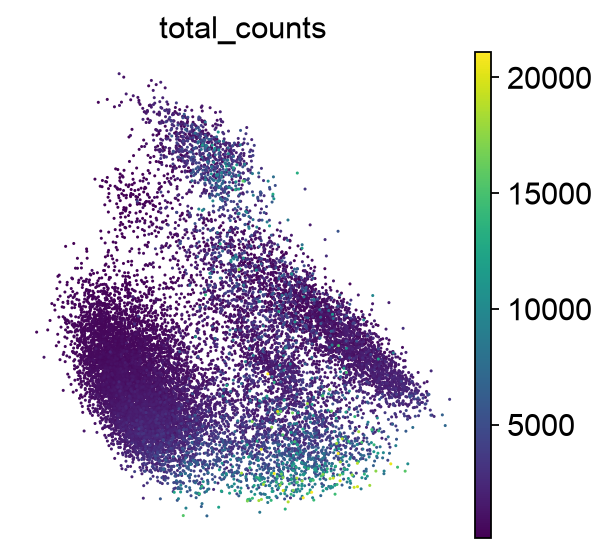

In [8]:
sc.pl.pca(adata, color="total_counts")

In [9]:
adata

AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'analytic_pearson_residuals', 'counts', 'log1p_norm', 'scran_normalization', 'soupX_counts', None (.X)

# t-SNE
- Graph-based non-linear dimensionality reduction technique which projects the high-dimensional data onto 2D or 3D components.
- The method defines a Gaussian probability distribution based on the high-dimensional Euclidean distances between data points.
- Subsequently, a Student t-distribution is used to recreate the probability distribution in a low dimensional space where the embeddings are optimized using gradient descent.

In [10]:
sc.tl.tsne(adata, use_rep="X_pca")

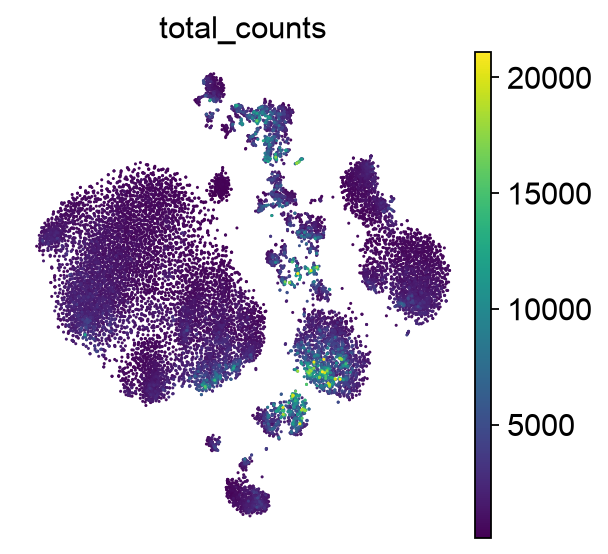

In [11]:
sc.pl.tsne(adata, color="total_counts")

# The axes in t-SNE have no meaning.
# Each point represents a single cell. Color represents the total number of transcripts (UMIs) detected in that cell.
# This plot helps reveal cellular subpopulations: tight clusters may correspond to distinct cell types or states.
# Unlike PCA, which preserves global variance, t-SNE emphasizes local structure.

In [12]:
adata

AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'pca', 'tsne'
    obsm: 'X_pca', 'X_tsne'
    varm: 'PCs'
    layers: 'analytic_pearson_residuals', 'counts', 'log1p_norm', 'scran_normalization', 'soupX_counts', None (.X)

# UMAP
- Graph-based, non-linear dimensionality reduction technique which is principally similar to t-SNE.
- It constructs a high-dimensional graph representation of the dataset and optimizes the low-dimensional graph representation to be as structurally similar as possible to the original graph.

In [13]:
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [14]:
adata

AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'pca', 'tsne', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: 'analytic_pearson_residuals', 'counts', 'log1p_

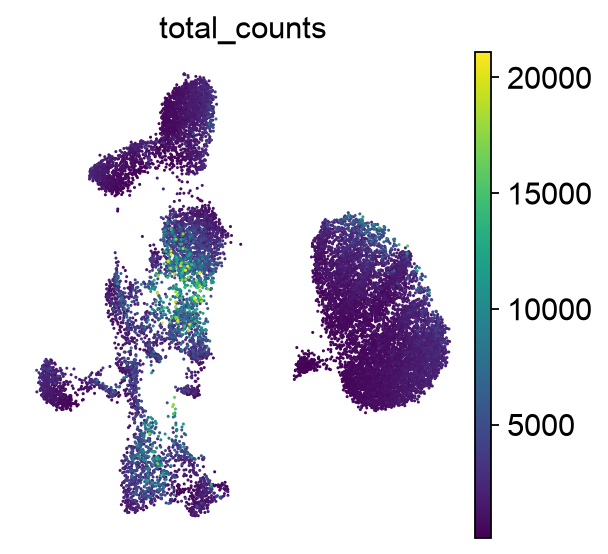

In [15]:
sc.pl.umap(adata, color="total_counts")

# The axes in UMAP have no meaning.
# Each point represents a single cell. Color represents the total number of transcripts (UMIs) detected in that cell.
# Like t-SNE, UMAP emphasizes local structure and the arrangement of its clusters depends on the initialization.
# It constructs a neighborhood graph based on PCA-reduced data, 
# then optimizes a low-dimensional layout that reflects relationships in the original high-dimensional space.

## Important points when interpreting t-SNE and UMAP
- t-SNE and UMAP preserve which cells are neighbors, not the distances between cells that are far apart.
- Cluster sizes and distance between clusters carry little meaning.
- Where cluster ends up relative to each other also depends on the initialization, so neighboring clusters in an embedding are no evidence that the populations are related.

In [16]:
sc.tl.umap(adata, init_pos="random", key_added="X_umap_random")

In [17]:
adata

AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'pca', 'tsne', 'neighbors', 'umap', 'X_umap_random'
    obsm: 'X_pca', 'X_tsne', 'X_umap', 'X_umap_random'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: 'analytic_pea

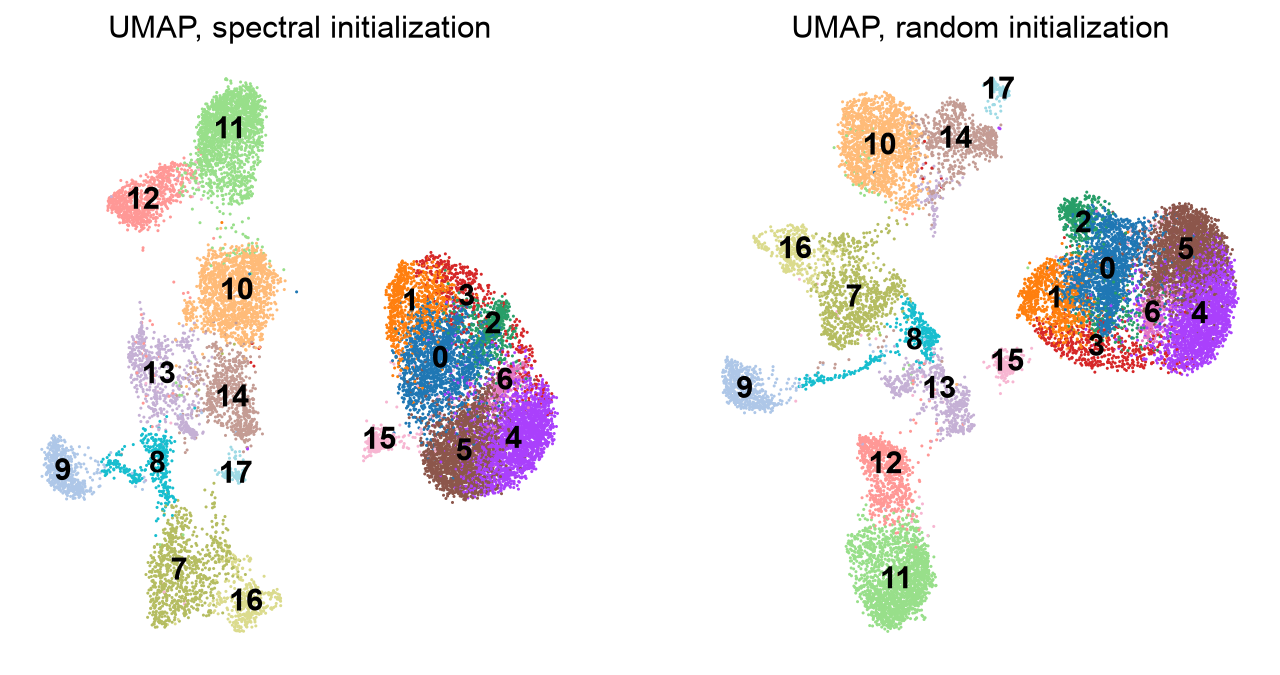

In [18]:
# Colouring both embeddings by the coarse Leiden clusters that we computed for SoupX during quality control
initializations = {
    "X_umap": "UMAP, spectral initialization",
    "X_umap_random": "UMAP, random initialization",
}

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (basis, title) in zip(axes, initializations.items(), strict=True):
    sc.pl.embedding(
        adata,
        basis=basis,
        color="soupx_groups",
        title=title,
        legend_loc="on data",
        ax=ax,
        show=False,
    )
plt.show()

In [19]:
# To quantify how much of the local structure survives in different initializations,
# we compute the neighborhood graph of every embedding
# and the fraction of the neighbors of every cell in the 50 principal components that it keeps,
# using the first two principal components as a linear reference.
embeddings = ad.AnnData(
    obsm={
        key: adata.obsm[key] for key in ["X_pca", "X_tsne", "X_umap", "X_umap_random"]
    }
) # Creating a new AnnData object containing only the coordinates from four dimensionality reduction runs
reference = adata.obsp["distances"] > 0 # If two cells are neighbors in the original high-dimensional space, the value is True or 1. If they are not, it is False or 0

preservation = {}
for title, kwargs in {
    "PCA, first two components": {"use_rep": "X_pca", "n_pcs": 2},
    "t-SNE, PCA initialization": {"use_rep": "X_tsne"},
    "UMAP, spectral initialization": {"use_rep": "X_umap"},
    "UMAP, random initialization": {"use_rep": "X_umap_random"},
}.items():
    sc.pp.neighbors(embeddings, **kwargs)
    neighbors = embeddings.obsp["distances"] > 0
    preservation[title] = neighbors.multiply(reference).sum() / reference.sum() 
    # neighbors.multiple(reference) finds overlaps. It returns 1 only if a pair of cells are neighbors in both original space and the lower-dimensional space
pd.Series(preservation, name="neighbor preservation").round(2)

PCA, first two components        0.03
t-SNE, PCA initialization        0.25
UMAP, spectral initialization    0.10
UMAP, random initialization      0.11
Name: neighbor preservation, dtype: float64

In [20]:
# From the above, no two-dimensional embedding keeps the neighborhoods of the data.
# t-SNE keeps the highest while PCA keeps almost none
# The initialization rearranges the clusters of UMAP but not the neighborhoods

# Inspecting quality control

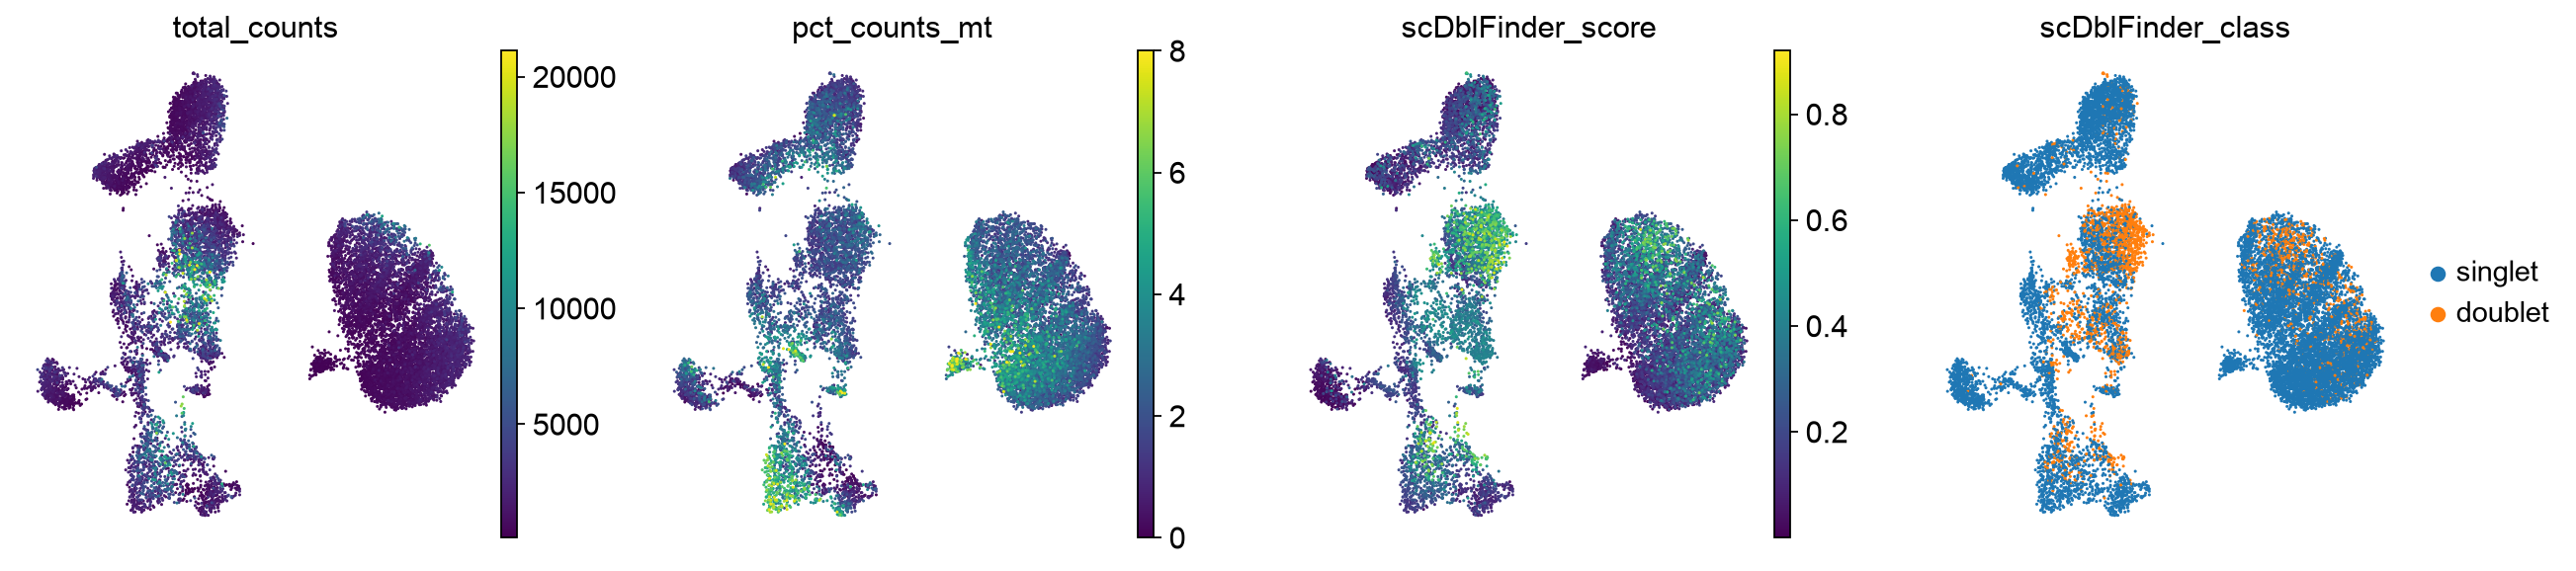

In [21]:
sc.pl.umap(
    adata,
    color=["total_counts", "pct_counts_mt", "scDblFinder_score", "scDblFinder_class"]
)

# Cells with a high doublet score are projected to the same region in the UMAP
# They should be removed to ensure as few doublets as possible are retained

In [22]:
adata

AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'pca', 'tsne', 'neighbors', 'umap', 'X_umap_random', 'soupx_groups_colors', 'scDblFinder_class_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap', 'X_umap_random'
    varm: 'PCs'
    obsp: 'dis

In [23]:
from pathlib import Path

output_dir = Path("../intermediate_data")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "dimensionality_reduction.h5ad"

adata.write_h5ad(output_path, compression="gzip")
print(f"Saved anndata after dimensionality reduction: {output_path.resolve()}")

Saved anndata after dimensionality reduction: /Users/ankitmukherjee/Bioinformatics/single_cell_analysis/scverse/05_scRNA_analysis/intermediate_data/dimensionality_reduction.h5ad
